In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

url = "https://raw.githubusercontent.com/Arbaaz-Shaikh/House-Prices-Prediction-in-Pune/master/Pune_House_Data.csv"
df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset Shape: (13320, 9)


,area_type,availability,size,society,total_sqft,bath,balcony,price,site_location
0,Super built-up Area,19-Dec,2 BHK,Coomee,1056,2.0,1.0,39.07,Alandi Road
1,Plot Area,Ready To Move,4 Bedroom,Theanmp,2600,5.0,3.0,120.00,Ambegaon Budruk
2,Built-up Area,Ready To Move,3 BHK,NaN,1440,2.0,3.0,62.00,Anandnagar
3,Super built-up Area,Ready To Move,3 BHK,Soiewre,1521,3.0,1.0,95.00,Aundh
4,Super built-up Area,Ready To Move,2 BHK,NaN,1200,2.0,1.0,51.00,Aundh Road


In [2]:
print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nSummary Statistics:")
display(df.describe(include="all"))

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

df = df.drop_duplicates()


Column Names:
['area_type', 'availability', 'size', 'society', 'total_sqft', 'bath', 'balcony', 'price', 'site_location']

Data Types:
area_type         object
availability      object
size              object
society           object
total_sqft        object
bath             float64
balcony          float64
price            float64
site_location     object
dtype: object

Summary Statistics:


,area_type,availability,size,society,total_sqft,bath,balcony,price,site_location
count,13320,13320,13304,7818,13320,13247.000000,12711.000000,13320.000000,13319
unique,4,81,31,2688,2117,NaN,NaN,NaN,97
top,Super built-up Area,Ready To Move,2 BHK,GrrvaGr,1200,NaN,NaN,NaN,Alandi Road
freq,8790,10581,5199,80,843,NaN,NaN,NaN,139
mean,NaN,NaN,NaN,NaN,NaN,2.692610,1.584376,112.565627,NaN
std,NaN,NaN,NaN,NaN,NaN,1.341458,0.817263,148.971674,NaN
min,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000,8.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,2.000000,1.000000,50.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,2.000000,2.000000,72.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,3.000000,2.000000,120.000000,NaN



Missing Values:
area_type           0
availability        0
size               16
society          5502
total_sqft          0
bath               73
balcony           609
price               0
site_location       1
dtype: int64

Duplicate Records: 11


In [3]:
def convert_area(value):
    try:
        value = str(value).replace(",", "").strip()
        numbers = re.findall(r"\d+\.?\d*", value)
        if not numbers:
            return np.nan
        return np.mean([float(x) for x in numbers[:2]])
    except:
        return np.nan

df["total_sqft"] = df["total_sqft"].apply(convert_area)

df["bhk"] = pd.to_numeric(
    df["size"].astype(str).str.extract(r"(\d+)")[0],
    errors="coerce"
)
df["price"] = pd.to_numeric(df["price"], errors="coerce")
df["bath"] = pd.to_numeric(df["bath"], errors="coerce")
df["site_location"] = df["site_location"].astype("string").str.strip()

df = df.dropna(
    subset=["total_sqft", "bhk", "bath", "price", "site_location"]
)

df = df[
    (df["total_sqft"] > 0) &
    (df["bhk"] > 0) &
    (df["bath"] > 0) &
    (df["price"] > 0)
].copy()

df = df[
    (df["total_sqft"] >= 200) &
    (df["total_sqft"] <= 10000) &
    (df["price"] <= 1000)
].copy()

print("Shape after cleaning:", df.shape)
display(df.head())

Shape after cleaning: (13139, 10)


,area_type,availability,size,society,total_sqft,bath,balcony,price,site_location,bhk
0,Super built-up Area,19-Dec,2 BHK,Coomee,1056.0,2.0,1.0,39.07,Alandi Road,2.0
1,Plot Area,Ready To Move,4 Bedroom,Theanmp,2600.0,5.0,3.0,120.00,Ambegaon Budruk,4.0
2,Built-up Area,Ready To Move,3 BHK,NaN,1440.0,2.0,3.0,62.00,Anandnagar,3.0
3,Super built-up Area,Ready To Move,3 BHK,Soiewre,1521.0,3.0,1.0,95.00,Aundh,3.0
4,Super built-up Area,Ready To Move,2 BHK,NaN,1200.0,2.0,1.0,51.00,Aundh Road,2.0


In [4]:
X = df[["total_sqft", "bhk", "bath", "site_location"]]
y = df["price"]

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
   total_sqft  bhk  bath    site_location
0      1056.0  2.0   2.0      Alandi Road
1      2600.0  4.0   5.0  Ambegaon Budruk
2      1440.0  3.0   2.0       Anandnagar
3      1521.0  3.0   3.0            Aundh
4      1200.0  2.0   2.0       Aundh Road

Target Variable:
0     39.07
1    120.00
2     62.00
3     95.00
4     51.00
Name: price, dtype: float64


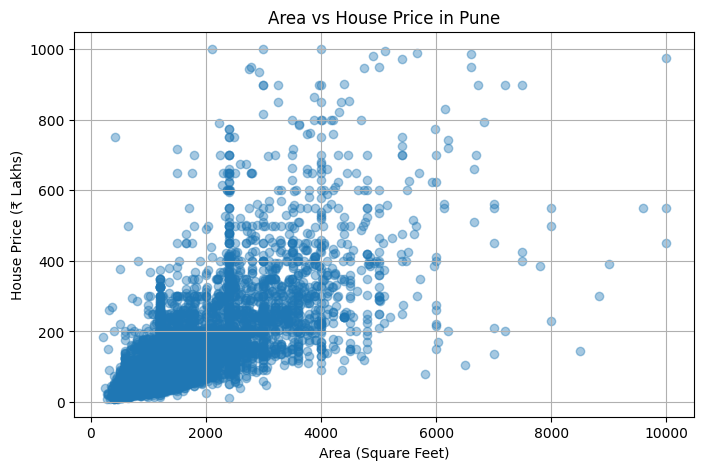

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df["total_sqft"],
    df["price"],
    alpha=0.4
)
plt.title("Area vs House Price in Pune")
plt.xlabel("Area (Square Feet)")
plt.ylabel("House Price (₹ Lakhs)")
plt.grid(True)
plt.show()

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 10511
Testing Records: 2628


In [7]:
numeric_features = ["total_sqft", "bhk", "bath"]
categorical_features = ["site_location"]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            SimpleImputer(strategy="median"),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)
regression_model = model.named_steps["regressor"]

print("Model trained successfully!")
print("Intercept:", regression_model.intercept_)
print("\nLearned Coefficients:", regression_model.coef_)

Model trained successfully!
Intercept: -57.56609282875935

Learned Coefficients: [  0.07828279   2.77158806  13.97911309   4.77542429   1.38898106
   5.17853858  10.71143019  14.24087033   2.68623225  -8.98277582
   3.56236099  -5.91897239   8.96995523  -7.4810689   -4.87294205
   3.56945752   4.35668216  -4.59012067   1.17103116  -2.09840392
  -6.74196634   0.306356    -6.3777696   -3.82703702  -6.02123918
  -4.26823882  -3.06273058  20.48213527  -0.98743524   3.47363548
  23.60631804 -17.78737541   6.8972246    3.85428497   4.8055254
   1.75220624  -1.2657565  -11.7278704  -13.99869061   5.28079703
  -1.53353524   8.5252259    0.86908795  12.78155168  -5.54870103
 -12.38062571  -6.9324499   -2.49859379   2.13374092   1.31789083
   0.86993341   3.06201222   6.042301     3.56296574   0.99390695
  -8.08385315 -11.16951019  -1.58037227  -0.40813202  -1.52959308
  -2.63168018   4.12235976   2.09929182 -11.16208375   3.48261391
   1.70461476  -3.24428045   3.47870448  15.95252548   2.78569

In [8]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Price (₹ Lakhs)": y_test.values,
    "Predicted Price (₹ Lakhs)": y_pred
})

display(comparison.head(10).round(2))

,Actual Price (₹ Lakhs),Predicted Price (₹ Lakhs)
0,225.00,109.57
1,115.00,122.19
2,160.00,168.38
3,65.26,78.39
4,375.00,257.27
5,83.87,103.94
6,125.00,156.37
7,44.00,56.83
8,52.00,59.51
9,45.00,65.23


In [9]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("MAE:", round(mae, 3), "Lakhs")
print("MSE:", round(mse, 3))
print("RMSE:", round(rmse, 3), "Lakhs")
print("R2 Score:", round(r2, 3))

MODEL PERFORMANCE
MAE: 39.192 Lakhs
MSE: 5400.71
RMSE: 73.49 Lakhs
R2 Score: 0.585


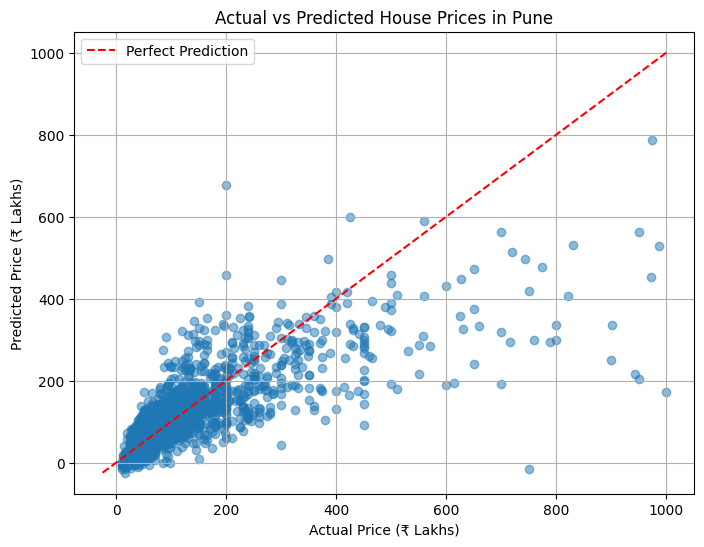

In [10]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted House Prices in Pune")
plt.xlabel("Actual Price (₹ Lakhs)")
plt.ylabel("Predicted Price (₹ Lakhs)")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
new_location = df["site_location"].mode()[0]

new_house = pd.DataFrame({
    "total_sqft": [1000],
    "bhk": [2],
    "bath": [2],
    "site_location": [new_location]
})

predicted_price = model.predict(new_house)

print("\nNEW HOUSE DETAILS")
print("Area: 1000 sq. ft.")
print("BHK: 2")
print("Bathrooms: 2")
print("Location:", new_location)

print(
    "\nPredicted House Price: ₹",
    round(predicted_price[0], 2),
    "Lakhs"
)


NEW HOUSE DETAILS
Area: 1000 sq. ft.
BHK: 2
Bathrooms: 2
Location: Baner road

Predicted House Price: ₹ 57.78 Lakhs
